Harshavarthan SB 24BAD033
11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training images : 60000
Test images     : 10000
Image dimensions: (28, 28) | dtype: uint8
Pixel range     : 0 to 255

Images per digit class (training set):
          0     1     2     3     4     5     6     7     8     9
count  5923  6742  5958  6131  5842  5421  5918  6265  5851  5949


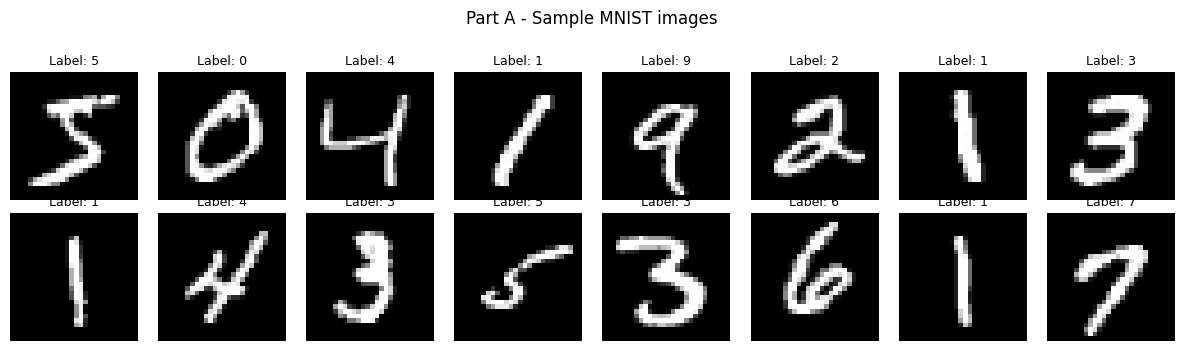


After normalization -> min: -1.0 max: 1.0
Reshaped training data: (60000, 28, 28, 1)
One batch from the pipeline: (256, 28, 28, 1)
Batches per epoch: 234


In [ ]:
print("Harshavarthan SB 24BAD033")
# Part A
import os, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import keras
from keras import layers

# Load the MNIST handwritten digit dataset
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()

# Explore the dataset: number of images and image dimensions
print("Training images :", x_train.shape[0])
print("Test images     :", x_test.shape[0])
print("Image dimensions:", x_train.shape[1:], "| dtype:", x_train.dtype)
print("Pixel range     :", x_train.min(), "to", x_train.max())
print("\nImages per digit class (training set):")
print(pd.Series(y_train).value_counts().sort_index().to_frame("count").T.to_string())

# Display sample images from the dataset
fig, axes = plt.subplots(2, 8, figsize=(12, 3.4))
for i, ax in enumerate(axes.flat):
    ax.imshow(x_train[i], cmap="gray")
    ax.set_title(f"Label: {y_train[i]}", fontsize=9)
    ax.axis("off")
plt.suptitle("Part A - Sample MNIST images", y=1.02)
plt.tight_layout()
plt.show()

# Normalize pixel values to the range [-1, 1]
x_train_norm = (x_train.astype("float32") - 127.5) / 127.5
print("\nAfter normalization -> min:", x_train_norm.min(), "max:", x_train_norm.max())

# Reshape images to (N, 28, 28, 1) - the (height, width, channels) format
x_train_norm = x_train_norm.reshape(-1, 28, 28, 1)
print("Reshaped training data:", x_train_norm.shape)

# Batch-wise data pipeline using tf.data
BUFFER_SIZE = x_train_norm.shape[0]
BATCH_SIZE = 256
train_dataset = (tf.data.Dataset.from_tensor_slices(x_train_norm)
                 .shuffle(BUFFER_SIZE)
                 .batch(BATCH_SIZE, drop_remainder=True)
                 .prefetch(tf.data.AUTOTUNE))

for batch in train_dataset.take(1):
    print("One batch from the pipeline:", batch.shape)
print("Batches per epoch:", len(train_dataset))


Harshavarthan SB 24BAD033
Generated image shape: (1, 28, 28, 1)


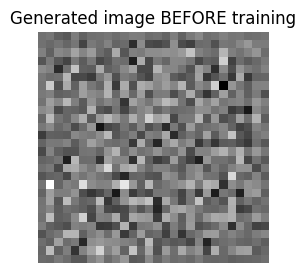

Model: "generator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 3136)           │       313,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 3136)           │        12,544 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 14, 14, 32)     │        32,768 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 14, 14, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 28, 28, 1)      │           513 │
│ (Conv2DTranspose)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 359,553 (1.37 MB)

 Trainable params: 353,217 (1.35 MB)

 Non-trainable params: 6,336 (24.75 KB)

In [ ]:
print("Harshavarthan SB 24BAD033")
# Part B
NOISE_DIM = 100          # length of the random noise (latent) vector

def build_generator():
    model = keras.Sequential(name="generator")
    model.add(keras.Input(shape=(NOISE_DIM,)))                       # noise vector input
    model.add(layers.Dense(7 * 7 * 64, use_bias=False))              # Dense: project noise
    model.add(layers.BatchNormalization())
    model.add(layers.LeakyReLU(0.2))
    model.add(layers.Reshape((7, 7, 64)))
    model.add(layers.Conv2DTranspose(32, 4, strides=2, padding="same", use_bias=False))   # 14x14
    model.add(layers.BatchNormalization())
    model.add(layers.LeakyReLU(0.2))
    model.add(layers.Conv2DTranspose(1, 4, strides=2, padding="same", activation="tanh")) # 28x28, [-1,1]
    return model

generator = build_generator()

# Generate an image from a random noise vector (before training)
noise = tf.random.normal([1, NOISE_DIM])
untrained_image = generator(noise, training=False)
print("Generated image shape:", untrained_image.shape)

plt.figure(figsize=(3, 3))
plt.imshow(untrained_image[0, :, :, 0], cmap="gray")
plt.title("Generated image BEFORE training")
plt.axis("off")
plt.show()

# Generator architecture and summary
generator.summary()


In [ ]:
print("Harshavarthan SB 24BAD033")
# Part C
def build_discriminator():
    model = keras.Sequential(name="discriminator")
    model.add(keras.Input(shape=(28, 28, 1)))
    model.add(layers.Conv2D(32, 4, strides=2, padding="same"))       # 14x14 feature maps
    model.add(layers.LeakyReLU(0.2))
    model.add(layers.Dropout(0.3))
    model.add(layers.Conv2D(64, 4, strides=2, padding="same"))       # 7x7 feature maps
    model.add(layers.LeakyReLU(0.2))
    model.add(layers.Dropout(0.3))
    model.add(layers.Flatten())
    model.add(layers.Dense(1, activation="sigmoid"))                 # real (1) / fake (0)
    return model

discriminator = build_discriminator()

# Compile the Discriminator: Adam optimizer + binary cross-entropy loss
discriminator.compile(optimizer=keras.optimizers.Adam(learning_rate=2e-4, beta_1=0.5),
                      loss="binary_crossentropy")

# Combine Generator and Discriminator to form the GAN: noise -> Generator -> Discriminator -> real/fake
gan_input = keras.Input(shape=(NOISE_DIM,))
gan = keras.Model(gan_input, discriminator(generator(gan_input)), name="gan")
gan.compile(optimizer=keras.optimizers.Adam(learning_rate=2e-4, beta_1=0.5),
            loss="binary_crossentropy")
# While the GAN is trained, only the Generator's weights are updated (see Part D),
# so the Discriminator stays fixed during the Generator step.

# Model summaries
print("========== GENERATOR ==========")
generator.summary()
print("\n========== DISCRIMINATOR ==========")
discriminator.summary()
print("\n========== COMBINED GAN ==========")
gan.summary()

# Discriminator's verdict on the untrained generator's image
print("\nDiscriminator score for untrained generated image (1 = real):",
      float(discriminator(untrained_image, training=False)[0, 0]))


Harshavarthan SB 24BAD033
========== GENERATOR ==========


Model: "generator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 3136)           │       313,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 3136)           │        12,544 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 14, 14, 32)     │        32,768 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 14, 14, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 28, 28, 1)      │           513 │
│ (Conv2DTranspose)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 359,553 (1.37 MB)

 Trainable params: 353,217 (1.35 MB)

...

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 100)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ generator (Sequential)          │ (None, 28, 28, 1)      │       359,553 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ discriminator (Sequential)      │ (None, 1)              │        36,513 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 396,066 (1.51 MB)

 Trainable params: 389,730 (1.49 MB)

 Non-trainable params: 6,336 (24.75 KB)


Discriminator score for untrained generated image (1 = real): 0.4994489252567291


Harshavarthan SB 24BAD033
Epoch 01/12 | D loss: 0.4753 | G loss: 1.1472 | 123s


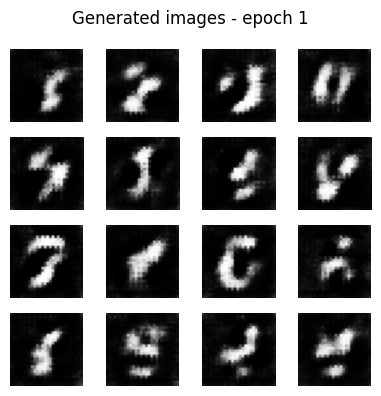

Epoch 02/12 | D loss: 0.5921 | G loss: 1.0409 | 235s
Epoch 03/12 | D loss: 0.6399 | G loss: 0.9400 | 377s


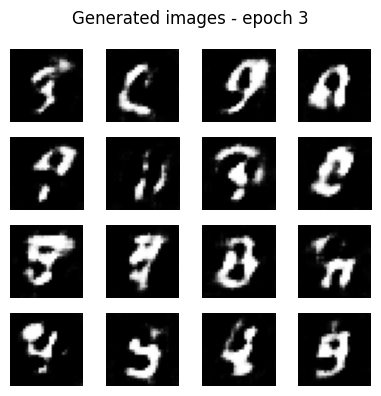

Epoch 04/12 | D loss: 0.6473 | G loss: 0.9168 | 520s
Epoch 05/12 | D loss: 0.6443 | G loss: 0.9231 | 630s
Epoch 06/12 | D loss: 0.6358 | G loss: 0.9491 | 740s


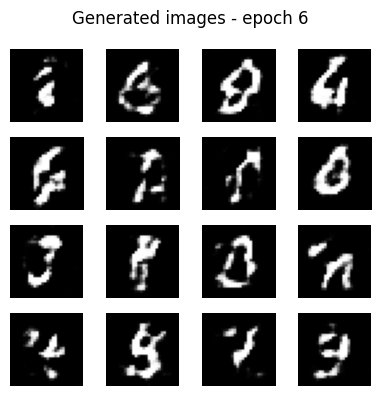

Epoch 07/12 | D loss: 0.6242 | G loss: 0.9746 | 849s
Epoch 08/12 | D loss: 0.6195 | G loss: 0.9979 | 958s
Epoch 09/12 | D loss: 0.6248 | G loss: 0.9942 | 1068s


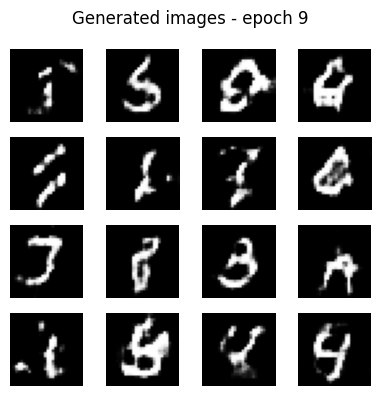

Epoch 10/12 | D loss: 0.6336 | G loss: 0.9728 | 1181s
Epoch 11/12 | D loss: 0.6402 | G loss: 0.9633 | 1290s
Epoch 12/12 | D loss: 0.6425 | G loss: 0.9543 | 1398s


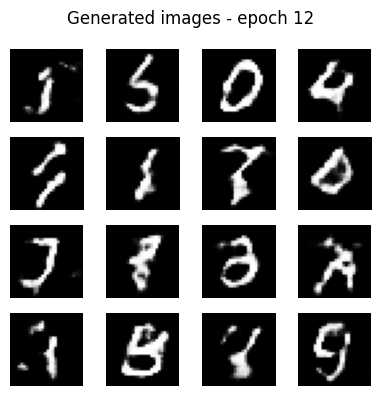

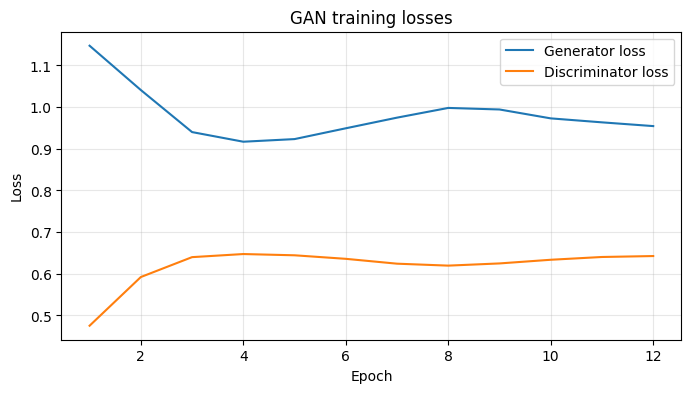

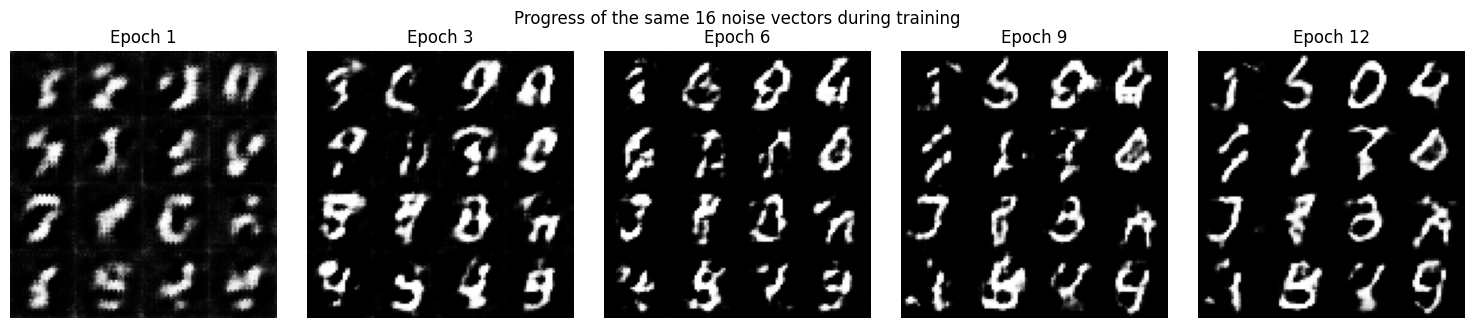

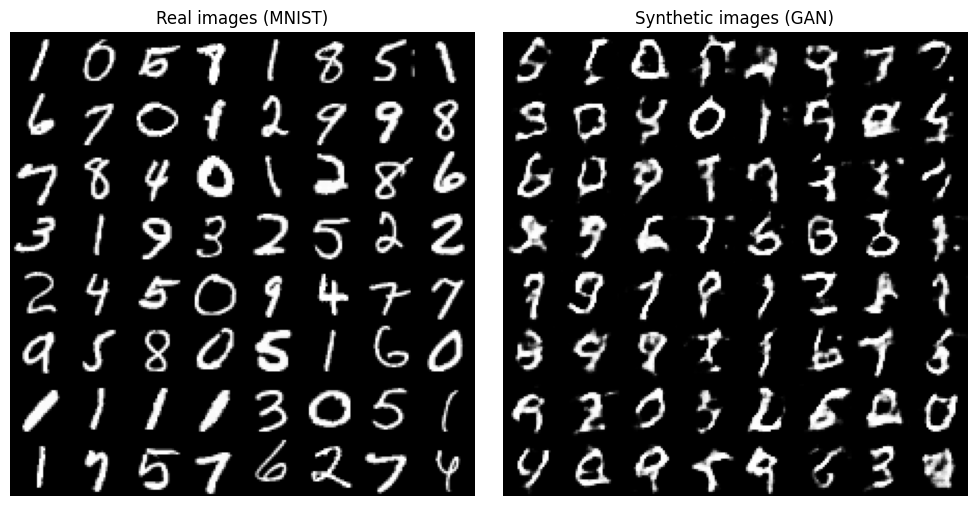

                                    Real images  Generated images
Mean pixel value                        -0.7319           -0.7407
Pixel std-dev                            0.6242            0.6097
Diversity (mean pairwise distance)      20.5267           19.8843
Discriminator score (1 = real)           0.4827            0.3743

Diversity ratio (generated / real): 0.969  (close to 1 -> no mode collapse)

Saved files: ['epoch_01.png', 'epoch_03.png', 'epoch_06.png', 'epoch_09.png', 'epoch_12.png', 'final_01.png', 'final_02.png', 'final_03.png', 'final_04.png', 'final_05.png', 'final_06.png', 'final_07.png', 'final_08.png', 'final_09.png', 'final_10.png', 'final_11.png', 'final_12.png', 'final_13.png', 'final_14.png', 'final_15.png', 'final_16.png', 'final_grid_8x8.png', 'generator_final.keras']


In [ ]:
print("Harshavarthan SB 24BAD033")
# Part D
EPOCHS = 12
SAMPLE_INTERVAL = 3                       # generate images every 3 epochs
NUM_EXAMPLES = 16
seed = tf.random.normal([NUM_EXAMPLES, NOISE_DIM])     # fixed noise to track progress
os.makedirs("generated_images", exist_ok=True)

def show_grid(images, title, n=4, save_path=None):
    images = (np.asarray(images)[:, :, :, 0] + 1) / 2.0          # back to [0, 1]
    fig, axes = plt.subplots(n, n, figsize=(4, 4))
    for img, ax in zip(images, axes.flat):
        ax.imshow(img, cmap="gray", vmin=0, vmax=1)
        ax.axis("off")
    plt.suptitle(title)
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=120)
    plt.show()

bce = keras.losses.BinaryCrossentropy()
d_optimizer = discriminator.optimizer                                  # optimizer set in compile()
g_optimizer = keras.optimizers.Adam(learning_rate=2e-4, beta_1=0.5)

@tf.function
def train_step(real_images):
    n = tf.shape(real_images)[0]

    # Train the Discriminator on real images (label 0.9, one-sided smoothing) and synthetic images (label 0)
    noise = tf.random.normal([n, NOISE_DIM])                           # Generator initialised with random noise
    with tf.GradientTape() as tape:
        fake_images = generator(noise, training=True)
        real_pred = discriminator(real_images, training=True)
        fake_pred = discriminator(fake_images, training=True)
        d_loss = 0.5 * (bce(tf.fill([n, 1], 0.9), real_pred) + bce(tf.zeros([n, 1]), fake_pred))
    d_grads = tape.gradient(d_loss, discriminator.trainable_variables)
    d_optimizer.apply(d_grads, discriminator.trainable_variables)

    # Train the Generator through the combined GAN model (target label 1 = "real")
    noise = tf.random.normal([n, NOISE_DIM])
    with tf.GradientTape() as tape:
        g_loss = bce(tf.ones([n, 1]), gan(noise, training=True))
    g_grads = tape.gradient(g_loss, generator.trainable_variables)    # only Generator weights are updated
    g_optimizer.apply(g_grads, generator.trainable_variables)
    return d_loss, g_loss

g_losses, d_losses = [], []
snapshots = {}

start = time.time()
for epoch in range(1, EPOCHS + 1):
    d_ep, g_ep = [], []
    for real_images in train_dataset:
        d_l, g_l = train_step(real_images)
        d_ep.append(d_l); g_ep.append(g_l)

    # Record Generator loss and Discriminator loss
    d_losses.append(float(tf.reduce_mean(d_ep))); g_losses.append(float(tf.reduce_mean(g_ep)))
    print(f"Epoch {epoch:02d}/{EPOCHS} | D loss: {d_losses[-1]:.4f} | G loss: {g_losses[-1]:.4f} "
          f"| {time.time() - start:.0f}s")

    # Generate synthetic images at regular training intervals
    if epoch == 1 or epoch % SAMPLE_INTERVAL == 0:
        snapshots[epoch] = generator(seed, training=False).numpy()
        show_grid(snapshots[epoch], f"Generated images - epoch {epoch}",
                  save_path=f"generated_images/epoch_{epoch:02d}.png")

# Loss curves
plt.figure(figsize=(8, 4))
plt.plot(range(1, EPOCHS + 1), g_losses, label="Generator loss")
plt.plot(range(1, EPOCHS + 1), d_losses, label="Discriminator loss")
plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.title("GAN training losses")
plt.legend(); plt.grid(alpha=0.3)
plt.show()

# Visualize generated images at different stages of training
stages = sorted(snapshots)
fig, axes = plt.subplots(1, len(stages), figsize=(3 * len(stages), 3.3))
for ax, ep in zip(axes, stages):
    grid = (snapshots[ep][:, :, :, 0] + 1) / 2.0
    rows = [np.hstack(grid[r * 4:(r + 1) * 4]) for r in range(4)]
    ax.imshow(np.vstack(rows), cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"Epoch {ep}"); ax.axis("off")
plt.suptitle("Progress of the same 16 noise vectors during training")
plt.tight_layout(); plt.show()

# Compare generated images with real images
final_noise = tf.random.normal([64, NOISE_DIM])
final_images = generator(final_noise, training=False).numpy()
real_sample = x_train_norm[np.random.choice(len(x_train_norm), 64, replace=False)]

def tile(imgs, n=8):
    imgs = (imgs[:, :, :, 0] + 1) / 2.0
    return np.vstack([np.hstack(imgs[r * n:(r + 1) * n]) for r in range(n)])

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(tile(real_sample), cmap="gray"); axes[0].set_title("Real images (MNIST)"); axes[0].axis("off")
axes[1].imshow(tile(final_images), cmap="gray"); axes[1].set_title("Synthetic images (GAN)"); axes[1].axis("off")
plt.tight_layout(); plt.show()

# Analyze quality and diversity of the generated images
def mean_pairwise_distance(imgs):
    flat = imgs.reshape(len(imgs), -1)
    d = np.linalg.norm(flat[:, None, :] - flat[None, :, :], axis=-1)
    return d.sum() / (len(imgs) * (len(imgs) - 1))

big_noise = tf.random.normal([500, NOISE_DIM])
gen_500 = generator(big_noise, training=False).numpy()
real_500 = x_train_norm[np.random.choice(len(x_train_norm), 500, replace=False)]
d_real = float(np.mean(discriminator(real_500, training=False)))
d_fake = float(np.mean(discriminator(gen_500, training=False)))

analysis = pd.DataFrame({
    "Real images": [real_500.mean(), real_500.std(), mean_pairwise_distance(real_500), d_real],
    "Generated images": [gen_500.mean(), gen_500.std(), mean_pairwise_distance(gen_500), d_fake],
}, index=["Mean pixel value", "Pixel std-dev", "Diversity (mean pairwise distance)",
          "Discriminator score (1 = real)"])
print(analysis.round(4).to_string())
print("\nDiversity ratio (generated / real): %.3f  (close to 1 -> no mode collapse)"
      % (analysis.loc["Diversity (mean pairwise distance)", "Generated images"] /
         analysis.loc["Diversity (mean pairwise distance)", "Real images"]))

# Save the final generated images
for i in range(NUM_EXAMPLES):
    plt.imsave(f"generated_images/final_{i + 1:02d}.png", (final_images[i, :, :, 0] + 1) / 2.0, cmap="gray")
plt.imsave("generated_images/final_grid_8x8.png", tile(final_images), cmap="gray")
generator.save("generated_images/generator_final.keras")
print("\nSaved files:", sorted(os.listdir("generated_images")))
